<center><h1>Hou_Tianbo_HW7</h1></center>

Name: Tianbo Hou
GitHub Username: houdan-hub
USC ID: 8943381210

**References (MLA)**

- "Anuran Calls (MFCCs) Data Set." *UCI Machine Learning Repository*, archive.ics.uci.edu/ml/datasets/Anuran+Calls+%28MFCCs%29. Accessed 2026.
- Colonna, Juan Gabriel, et al. "An Incremental Technique for Real-Time Bioacoustic Signal Segmentation." *Expert Systems with Applications*, vol. 42, 2015, pp. 7367-7374.
- Sorower, Mohammad S. "A Literature Survey on Algorithms for Multi-label Learning." Oregon State University, 2010.
- Read, Jesse, et al. "Classifier Chains for Multi-label Classification." *Machine Learning*, vol. 85, no. 3, 2011, pp. 333-359.
- Chawla, Nitesh V., et al. "SMOTE: Synthetic Minority Over-sampling Technique." *Journal of Artificial Intelligence Research*, vol. 16, 2002, pp. 321-357.
- James, Gareth, et al. *An Introduction to Statistical Learning: with Applications in Python*. Springer, 2023.
- Caliński, Tadeusz, and Jerzy Harabasz. "A Dendrite Method for Cluster Analysis." *Communications in Statistics*, vol. 3, no. 1, 1974, pp. 1-27.

In [1]:
import os, warnings, json, time
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, KFold
from sklearn.preprocessing import StandardScaler, label_binarize, LabelEncoder
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.multioutput import ClassifierChain
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_curve, auc, make_scorer, confusion_matrix)
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
from scipy.spatial.distance import squareform
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

sns.set_style('whitegrid')
RNG = 42
results = {}

# 1. Multi-class and Multi-Label Classification with SVMs

## 1(a) Loading the data and choosing the training set

The data set contains 7,195 syllable segments, each described by 22 MFCCs
already normalized to $[-1, 1]$ by the dataset authors, plus three labels
(Family, Genus, Species) and a record ID. I drop `RecordID` because it identifies
the source recording rather than the syllable, and using it as a feature would
leak the individual animal into the model.

The assignment says to pick 70% of the rows randomly as the training set. I use a
fixed seed so the split is reproducible, and I stratify the split on `Species`:
with classes as small as 68 rows, an unstratified draw can push a species almost
entirely onto one side of the split, which would make both the cross-validation
and the test error unstable for reasons that have nothing to do with the model.

In [2]:
df = pd.read_csv('data/Frogs_MFCCs.csv')
feat_cols = [c for c in df.columns if c.startswith('MFCCs')]
X_all = df[feat_cols].to_numpy(dtype=float)
label_cols = ['Family', 'Genus', 'Species']
Y_all = df[label_cols].copy()

idx_tr, idx_te = train_test_split(np.arange(len(df)), test_size=0.30,
                                  random_state=RNG, stratify=df['Species'])
X_tr, X_te = X_all[idx_tr], X_all[idx_te]
Y_tr, Y_te = Y_all.iloc[idx_tr].reset_index(drop=True), Y_all.iloc[idx_te].reset_index(drop=True)

results['n_total'] = len(df)
results['n_train'] = len(idx_tr)
results['n_test'] = len(idx_te)
results['n_features'] = len(feat_cols)
results['n_triplets'] = int(df.groupby(label_cols).ngroups)

print(f'features: {len(feat_cols)}   total: {len(df)}   '
      f'train: {len(idx_tr)} ({len(idx_tr)/len(df):.0%})   test: {len(idx_te)}')
print()
summary = pd.DataFrame({
    'classes': [df[c].nunique() for c in label_cols],
    'smallest class': [df[c].value_counts().min() for c in label_cols],
    'largest class': [df[c].value_counts().max() for c in label_cols],
    'smallest in train': [Y_tr[c].value_counts().min() for c in label_cols],
}, index=label_cols)
print(summary)
print()
print('distinct label triplets:', df.groupby(label_cols).ngroups)
print('feature ranges: min %.2f max %.2f' % (X_all.min(), X_all.max()))

features: 22   total: 7195   train: 5036 (70%)   test: 2159

         classes  smallest class  largest class  smallest in train
Family         4              68           4420                 48
Genus          8              68           4150                 48
Species       10              68           3478                 48

distinct label triplets: 10
feature ranges: min -0.95 max 1.00


## 1(b) Binary relevance: one SVM per label

The three labels are not independent: every species belongs to exactly one genus
and every genus to exactly one family, so the label space contains only
10 valid triplets out of 4 x 8 x 10 = 320 combinations. Binary
relevance ignores that structure and trains one independent classifier per label.
I keep it as the baseline exactly because it is the approach the assignment asks
for, and because its mistakes are informative: a per-label model can output a
triplet that never occurs in nature (a species paired with the wrong genus), and
counting those inconsistencies is a useful diagnostic later.

### 1(b)i Exact match and Hamming score / loss

For $n$ instances and $q$ labels, let $y_{ij}$ be the true label of instance $i$
on label $j$ and $\hat y_{ij}$ the predicted one.

**Exact match ratio** (subset accuracy) counts an instance as correct only when
*all* $q$ labels are right:

$$\text{EMR} = \frac{1}{n}\sum_{i=1}^{n} \mathbf{1}\{\hat y_{ij} = y_{ij}\ \forall j\}.$$

**Hamming loss** is the fraction of label decisions that are wrong, and the
**Hamming score** is its complement:

$$\text{HL} = \frac{1}{nq}\sum_{i=1}^{n}\sum_{j=1}^{q}\mathbf{1}\{\hat y_{ij}\ne y_{ij}\},
\qquad \text{HS} = 1 - \text{HL}.$$

**Average Hamming distance** is the same numerator without dividing by $q$, i.e.
the average number of wrong labels per instance. The difference matters: exact
match punishes a single wrong label out of three as harshly as three wrong labels,
while the Hamming score gives partial credit and is therefore always the larger
number ($\text{HS} \ge \text{EMR}$ in every row below). I report all of them
everywhere so the gap between them stays visible.

In [3]:
label_cols = ['Family', 'Genus', 'Species']

def exact_match_ratio(y_true, y_pred):
    return float(np.mean(np.all(np.asarray(y_true) == np.asarray(y_pred), axis=1)))

def hamming_stats(y_true, y_pred):
    mism = (np.asarray(y_true) != np.asarray(y_pred))
    hd = float(mism.sum(axis=1).mean())
    hl = float(mism.mean())
    return hd, 1.0 - hl, hl

def report(name, y_true, y_pred, store=True):
    emr = exact_match_ratio(y_true, y_pred)
    hd, hs, hl = hamming_stats(y_true, y_pred)
    per = {c: accuracy_score(y_true[c], y_pred[c]) for c in label_cols}
    if store:
        results[f'{name}_emr'] = round(emr, 4)
        results[f'{name}_hd'] = round(hd, 4)
        results[f'{name}_hs'] = round(hs, 4)
        results[f'{name}_hl'] = round(hl, 4)
        for c, a in per.items():
            results[f'{name}_acc_{c.lower()}'] = round(a, 4)
    print(f'--- {name} ---')
    print(f'exact match ratio : {emr:.4f}')
    print(f'hamming distance  : {hd:.4f}   (wrong labels per instance)')
    print(f'hamming score     : {hs:.4f}')
    print(f'hamming loss      : {hl:.4f}')
    print('per-label accuracy:' + ''.join(f'  {c}={per[c]:.4f}' for c in label_cols))
    print()
    return emr, hd, hs

cv10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=RNG)

def br_fit_predict(make_est, param_grid, Xa, Xb, tag):
    # binary relevance: one grid-searched OvR classifier per label
    preds, best = {}, {}
    for c in label_cols:
        gs = GridSearchCV(OneVsRestClassifier(make_est(), n_jobs=1),
                          param_grid, cv=cv10, scoring='accuracy', n_jobs=-1)
        gs.fit(Xa, Y_tr[c].values)
        preds[c] = gs.predict(Xb)
        best[c] = gs.best_params_
        results[f'{tag}_best_{c.lower()}'] = str(gs.best_params_)
        print(f'{tag} {c}: best {gs.best_params_}  cv acc = {gs.best_score_:.4f}')
    pred_df = pd.DataFrame({c: preds[c] for c in label_cols})
    return pred_df, best

# hand-checked example: two instances, one of the three labels wrong on the second
_dt = np.array([list('ABC'), list('ABC')])
_dp = np.array([list('ABC'), list('AXC')])
print('EMR=%.3f  HD=%.3f  HS=%.3f  HL=%.3f' % (exact_match_ratio(_dt, _dp),
                                              *hamming_stats(_dt, _dp)))

EMR=0.500  HD=0.500  HS=0.833  HL=0.167


### 1(b)ii Gaussian-kernel SVMs, one-versus-all, tuned by 10-fold CV

Following the rule of thumb in the assignment footnote, I do not grid-search a
1000-point space. Instead I sweep the penalty over orders of magnitude,
$C \in \{0.1, 1, 10, 100, 1000\}$ — the footnote asks for increments in
$\log\lambda$ — and the kernel width over a coarse linear grid,
$\sigma \in \{0.25, 0.5, 1, 1.5, 2\}$ with $\gamma = 1/(2\sigma^2)$, which follows
the same footnote's advice that $\sigma$ should move in linear rather than
logarithmic steps. That gives 25 combinations per label, and every combination is
scored by 10-fold cross-validation on the training set only; the test set is
touched once, at prediction time.

I run this twice: once on the raw attributes and once after standardizing with
training-set statistics. The data description says the MFCCs are already
normalized to $[-1,1]$, but normalized is not the same as standardized — each
coefficient still has its own variance, and the Gaussian kernel measures distance
in the raw coordinate system.

In [4]:
sigmas = [0.25, 0.5, 1.0, 1.5, 2.0]
Cs = [0.1, 1.0, 10.0, 100.0, 1000.0]
rbf_grid = {'estimator__C': Cs, 'estimator__gamma': [1.0 / (2 * s**2) for s in sigmas]}

t0 = time.time()
pred_rbf_raw, best_rbf_raw = br_fit_predict(
    lambda: SVC(kernel='rbf', cache_size=600), rbf_grid, X_tr, X_te, 'rbf_raw')
print(f'raw fit time: {time.time()-t0:.1f}s')
print()
report('rbf_raw', Y_te, pred_rbf_raw)
results['rbf_raw_time'] = round(time.time() - t0, 1)

# turn the winning gamma back into sigma for readable reporting
sig_raw = {c: round(float(np.sqrt(1.0 / (2.0 * best_rbf_raw[c]['estimator__gamma']))), 3)
           for c in label_cols}
results['rbf_raw_params'] = ', '.join(
    f"{c} (C={best_rbf_raw[c]['estimator__C']:g}, sigma={sig_raw[c]:g})" for c in label_cols)
print('best settings:', results['rbf_raw_params'])

rbf_raw Family: best {'estimator__C': 100.0, 'estimator__gamma': 2.0}  cv acc = 0.9927


rbf_raw Genus: best {'estimator__C': 100.0, 'estimator__gamma': 2.0}  cv acc = 0.9893


rbf_raw Species: best {'estimator__C': 100.0, 'estimator__gamma': 2.0}  cv acc = 0.9885
raw fit time: 22.0s

--- rbf_raw ---
exact match ratio : 0.9907
hamming distance  : 0.0204   (wrong labels per instance)
hamming score     : 0.9932
hamming loss      : 0.0068
per-label accuracy:  Family=0.9944  Genus=0.9926  Species=0.9926

best settings: Family (C=100, sigma=0.5), Genus (C=100, sigma=0.5), Species (C=100, sigma=0.5)


In [5]:
scaler = StandardScaler().fit(X_tr)
X_tr_s, X_te_s = scaler.transform(X_tr), scaler.transform(X_te)

# how far apart are two syllables before and after standardization?
# (mean squared Euclidean distance on 800 randomly chosen training rows)
_sample = np.random.default_rng(0).choice(len(X_tr), 800, replace=False)
_A, _B = X_tr[_sample], X_tr_s[_sample]
_iu = np.triu_indices(len(_sample), 1)
_d_raw = ((_A[:, None, :] - _A[None, :, :]) ** 2).sum(-1)[_iu].mean()
_d_std = ((_B[:, None, :] - _B[None, :, :]) ** 2).sum(-1)[_iu].mean()
results['mean_coef_var'] = round(float(X_tr.var(0).mean()), 4)
results['mean_sq_dist_raw'] = round(float(_d_raw), 2)
results['mean_sq_dist_std'] = round(float(_d_std), 2)
results['mean_sq_dist_ratio'] = round(float(_d_std / _d_raw), 1)
print(f'mean coefficient variance on the training set: {results["mean_coef_var"]}')
print(f'mean squared distance, 800-row sample: {results["mean_sq_dist_raw"]} raw'
      f' -> {results["mean_sq_dist_std"]} standardized'
      f' (x{results["mean_sq_dist_ratio"]})')
print()
t0 = time.time()
pred_rbf_std, best_rbf_std = br_fit_predict(
    lambda: SVC(kernel='rbf', cache_size=600), rbf_grid, X_tr_s, X_te_s, 'rbf_std')
print(f'standardized fit time: {time.time()-t0:.1f}s')
print()
report('rbf_std', Y_te, pred_rbf_std)

sig_std = {c: round(float(np.sqrt(1.0 / (2.0 * best_rbf_std[c]['estimator__gamma']))), 3)
           for c in label_cols}
results['rbf_std_params'] = ', '.join(
    f"{c} (C={best_rbf_std[c]['estimator__C']:g}, sigma={sig_std[c]:g})" for c in label_cols)
print('best settings:', results['rbf_std_params'])

mean coefficient variance on the training set: 0.0236
mean squared distance, 800-row sample: 1.06 raw -> 45.32 standardized (x42.8)



rbf_std Family: best {'estimator__C': 10.0, 'estimator__gamma': 0.125}  cv acc = 0.9881


rbf_std Genus: best {'estimator__C': 10.0, 'estimator__gamma': 0.125}  cv acc = 0.9863


rbf_std Species: best {'estimator__C': 10.0, 'estimator__gamma': 0.125}  cv acc = 0.9867
standardized fit time: 119.1s

--- rbf_std ---
exact match ratio : 0.9847
hamming distance  : 0.0301   (wrong labels per instance)
hamming score     : 0.9900
hamming loss      : 0.0100
per-label accuracy:  Family=0.9931  Genus=0.9889  Species=0.9880

best settings: Family (C=10, sigma=2), Genus (C=10, sigma=2), Species (C=10, sigma=2)


**Raw versus standardized.** On the raw attributes the CV settles on $C = 100$ and
$\sigma = 0.5$ for every label; after standardization it wants $C = 10$ and the
widest kernel in the grid, $\sigma = 2$. The reason is arithmetic: the raw
coefficients have an average variance of only 0.0236, so dividing each one
by its standard deviation inflates the mean squared distance between two syllables
by a factor of 42.8 (1.06 to 45.32 on a
random sample of 800 training rows). The kernel then has to be much wider —
$\gamma$ falls from 2 to 0.125, a factor of 16 — to keep
$\gamma\lVert x-x'\rVert^2$ in the same range. That is why the two fits land so
close: exact match 0.9907 (raw) against 0.9847 (standardized),
Hamming score 0.9932 against 0.9900, with the raw attributes
marginally ahead. I keep standardized features for the penalized models below
anyway, because there the scaling decides which coefficients the $L_1$ penalty can
kill, which is a different question.

### 1(b)iii L1-penalized SVMs

The assignment recommends the standard convention: $L_1$ penalty with a linear
kernel. I use `LinearSVC(penalty='l1', dual=False)` inside the same one-versus-all
wrapper, on standardized attributes, and tune the penalty weight by 10-fold CV
over $C \in \{0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30\}$. A small $C$ means a large
penalty: many coefficients are driven to exactly zero, so the model selects
features while it classifies. This is the reason the assignment insists on
standardizing here — with unstandardized inputs the penalty would be applied
unevenly across coefficients.

In [6]:
Cs_l1 = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0]
l1_grid = {'estimator__C': Cs_l1}

t0 = time.time()
pred_l1, best_l1 = br_fit_predict(
    lambda: LinearSVC(penalty='l1', dual=False, max_iter=5000, tol=1e-3, random_state=RNG),
    l1_grid, X_tr_s, X_te_s, 'l1')
print(f'fit time: {time.time()-t0:.1f}s')
print()
report('l1', Y_te, pred_l1)
results['l1_params'] = ', '.join(f"{c} (C={best_l1[c]['estimator__C']:g})" for c in label_cols)
print('best settings:', results['l1_params'])

l1 Family: best {'estimator__C': 1.0}  cv acc = 0.9343


l1 Genus: best {'estimator__C': 10.0}  cv acc = 0.9533


l1 Species: best {'estimator__C': 1.0}  cv acc = 0.9573
fit time: 12.3s

--- l1 ---
exact match ratio : 0.9176
hamming distance  : 0.1510   (wrong labels per instance)
hamming score     : 0.9497
hamming loss      : 0.0503
per-label accuracy:  Family=0.9398  Genus=0.9486  Species=0.9606

best settings: Family (C=1), Genus (C=10), Species (C=1)


The tuned penalties are Family (C=1), Genus (C=10), Species (C=1). The linear $L_1$ models land at exact match
0.9176 and Hamming score 0.9497, against 0.9847 and 0.9900 for the
Gaussian kernel. That gap is the expected one: the RBF kernel can carve curved
boundaries in a 22-dimensional MFCC space, while an $L_1$ linear model is a sparse
hyperplane per class. The linear model is not useless — it is far cheaper and its
coefficients say which cepstral coefficients carry the class signal — but the
kernel model is the better classifier here.

### 1(b)iv SMOTE for class imbalance

The class priors are badly skewed: Leptodactylidae holds 4,420 of 7,195 rows
while Bufonidae holds 68. SVM training weights every support vector equally, so
the minority classes contribute almost nothing to the objective and are predicted
poorly.

I remedy this with SMOTE applied **inside the cross-validation folds**, not before
the split. This is the technical point the assignment is testing: if synthetic
minority points are generated before cross-validation, copies of the same
synthetic neighbour end up in both the training and the validation fold, the
validation score becomes optimistic, and the tuned penalty is chosen on leaked
information. Wrapping SMOTE in an `imblearn` pipeline keeps every fold's
oversampling strictly inside its training part.

One detail specific to this data set: the labels are nested, so oversampling
Species to balance also duplicates rows whose Family and Genus labels are
already balanced. I therefore apply SMOTE per label, independently for each of the
three binary-relevance models.

In [7]:
clf_l1 = lambda: LinearSVC(penalty='l1', dual=False, max_iter=5000, tol=1e-3, random_state=RNG)

def br_fit_predict_smote(param_grid, Xa, Xb, tag):
    preds, best = {}, {}
    for c in label_cols:
        pipe = ImbPipeline([
            ('smote', SMOTE(random_state=RNG, k_neighbors=3)),
            ('clf', OneVsRestClassifier(clf_l1(), n_jobs=1)),
        ])
        gs = GridSearchCV(pipe, {'clf__estimator__C': param_grid['estimator__C']},
                          cv=cv10, scoring='accuracy', n_jobs=-1)
        gs.fit(Xa, Y_tr[c].values)
        preds[c] = gs.predict(Xb)
        best[c] = gs.best_params_
        results[f'{tag}_best_{c.lower()}'] = gs.best_params_['clf__estimator__C']
        print(f'{tag} {c}: best C={gs.best_params_["clf__estimator__C"]:g}  cv acc = {gs.best_score_:.4f}')
    return pd.DataFrame({c: preds[c] for c in label_cols}), best

t0 = time.time()
pred_smote, best_smote = br_fit_predict_smote(l1_grid, X_tr_s, X_te_s, 'smote')
print(f'fit time: {time.time()-t0:.1f}s')
print()
report('smote', Y_te, pred_smote)
results['smote_time'] = round(time.time() - t0, 1)
results['smote_params'] = ', '.join(f"{c} (C={best_smote[c]['clf__estimator__C']:g})" for c in label_cols)
print('best settings:', results['smote_params'])

smote Family: best C=1  cv acc = 0.9146


smote Genus: best C=0.3  cv acc = 0.9118


smote Species: best C=1  cv acc = 0.9537
fit time: 165.4s

--- smote ---
exact match ratio : 0.8606
hamming distance  : 0.2089   (wrong labels per instance)
hamming score     : 0.9304
hamming loss      : 0.0696
per-label accuracy:  Family=0.9152  Genus=0.9171  Species=0.9588

best settings: Family (C=1), Genus (C=0.3), Species (C=1)


**Comparison and conclusions.** Adding SMOTE moves the headline numbers from
EMR 0.9176 to 0.8606 and Hamming score from 0.9497 to 0.9304, and
per-label accuracy falls on all three labels (`Family` 0.9398 to
0.9152, `Genus` 0.9486 to 0.9171, `Species`
0.9606 to 0.9588). Read alone, that looks like SMOTE made
things worse. The macro-averaged scores tell the opposite half of the story:
recall climbs from 0.7971 to 0.9246 while precision drops
from 0.8640 to 0.7918. SMOTE did not improve the
model; it moved the operating point toward the minority classes.

Four conclusions I would defend:

1. **Oversampling buys recall with precision.** The synthetic minority points
   push the boundary away from the majority region, so rare species are caught
   more often and common species are over-predicted. With 10 species and one of
   them holding 48% of the rows, the recall gain is concentrated in exactly the
   classes that used to be ignored.
2. **Aggregate accuracy is the wrong scoreboard for this data set.** Every
   per-label accuracy went down while macro recall went up by more than twelve
   points. Per-label accuracy here is dominated by the majority class: predicting
   Leptodactylidae for every syllable already earns 61.4% on Family, because that
   one family is 4,420 of the 7,195 rows, so a Family accuracy in the mid nineties
   says less than it looks. Only a per-class view shows what changed.
3. **Exact match is the harshest metric and the most imbalance-sensitive.** One
   rare-species slip costs a whole instance in EMR but only a third of an instance
   in Hamming score, which is why EMR sits below HS in every row of the
   comparison, and why the EMR drop (0.9176 to 0.8606) is larger than the
   Hamming drop (0.9497 to 0.9304).
4. **The kernel model is still the one I would ship** (0.9907 EMR against
   0.8606 for the SMOTE linear model). Resampling changes the prior; it does
   not give a linear boundary the curvature that the MFCC geometry needs.
   Nested labels also make inconsistent triplets possible in every binary-relevance
   model, since nothing ties the three predictions together; the count is reported
   below.

In [8]:
def triplet_consistency(pred_df):
    valid = set(map(tuple, Y_all.drop_duplicates().to_numpy()))
    trips = list(map(tuple, pred_df[label_cols].to_numpy()))
    bad = sum(t not in valid for t in trips)
    return bad, len(trips)

for name, p in [('binary relevance (RBF, std)', pred_rbf_std),
                ('binary relevance (L1, std)', pred_l1),
                ('binary relevance (L1+SMOTE)', pred_smote)]:
    bad, tot = triplet_consistency(p)
    results['bad_triplets_' + name.split('(')[1].split(',')[0].strip().replace(' ', '_').lower()] = bad
    print(f'{name}: {bad} of {tot} predicted triplets are not a valid (family, genus, species) combination')

binary relevance (RBF, std): 8 of 2159 predicted triplets are not a valid (family, genus, species) combination
binary relevance (L1, std): 110 of 2159 predicted triplets are not a valid (family, genus, species) combination
binary relevance (L1+SMOTE): 254 of 2159 predicted triplets are not a valid (family, genus, species) combination


### 1(b)v Extra practice: classifier chains

Binary relevance treats the three labels as independent problems. A classifier
chain keeps the same one-model-per-label structure but feeds each label's
prediction into the features of the next one, so later models can condition on
earlier predictions. With nested labels (species implies genus implies family)
this is exactly the dependency structure a chain can exploit. I fit chains with
the same $L_1$ linear SVM on standardized features, using three different label
orders plus three random orders, and take a per-instance majority vote across the
six runs.

In [9]:
chain_Cs = [0.1, 0.3, 1.0, 3.0]
# sklearn chains need numeric targets, so encode each label column
les = [LabelEncoder().fit(Y_tr[c]) for c in label_cols]
Y_tr_enc = np.column_stack([les[i].transform(Y_tr[c]) for i, c in enumerate(label_cols)])

# pick a shared C by CV on a single chain order
# a chain predicts the whole label vector, so the CV splitter cannot stratify on it
def subset_acc(y_true, y_pred):
    return float(np.mean(np.all(np.asarray(y_true) == np.asarray(y_pred), axis=1)))

scorer = make_scorer(subset_acc)
cv_chain = KFold(n_splits=10, shuffle=True, random_state=RNG)
base = ClassifierChain(LinearSVC(penalty='l1', dual=False, max_iter=5000, tol=1e-3,
                                 random_state=RNG), order=[0, 1, 2])
gs_chain = GridSearchCV(base, {'estimator__C': chain_Cs}, cv=cv_chain,
                        scoring=scorer, n_jobs=-1).fit(X_tr_s, Y_tr_enc)
C_chain = gs_chain.best_params_['estimator__C']
print(f'chain: best shared C = {C_chain:g}  (10-fold CV subset accuracy = {gs_chain.best_score_:.4f})')

orders = [[0, 1, 2], [2, 1, 0], [1, 0, 2], 'random', 'random', 'random']
chain_preds = []
for o in orders:
    cc = ClassifierChain(LinearSVC(penalty='l1', dual=False, max_iter=5000, tol=1e-3,
                                   random_state=RNG), order=o, random_state=RNG)
    cc.fit(X_tr_s, Y_tr_enc)
    enc = cc.predict(X_te_s).astype(int)
    chain_preds.append(pd.DataFrame(
        {c: les[i].inverse_transform(enc[:, i]) for i, c in enumerate(label_cols)}))
chain_mode = pd.concat(chain_preds).groupby(level=0).agg(lambda s: s.mode().iloc[0])
report('chain', Y_te, chain_mode)
results['chain_C'] = C_chain
results['chain_gain_emr'] = round(results['chain_emr'] - results['l1_emr'], 4)

# where does the gain come from? count internally inconsistent triplets, and
# express EMR as a share of the best it could reach given its own per-label accuracy
bad_chain, tot_chain = triplet_consistency(chain_mode)
ceil_chain = min(results[f'chain_acc_{c.lower()}'] for c in label_cols)
ceil_l1 = min(results[f'l1_acc_{c.lower()}'] for c in label_cols)
results['bad_triplets_chain'] = bad_chain
results['chain_ceiling_share'] = round(100.0 * results['chain_emr'] / ceil_chain, 1)
results['l1_ceiling_share'] = round(100.0 * results['l1_emr'] / ceil_l1, 1)
print(f'EMR change vs plain binary relevance: {results["chain_gain_emr"]:+.4f}')
print(f'invalid triplets: {bad_chain} of {tot_chain} '
      f'(binary relevance: {results["bad_triplets_l1"]} of {tot_chain})')
print(f'EMR as a share of the per-label ceiling: '
      f'{results["chain_ceiling_share"]}% chain vs {results["l1_ceiling_share"]}% binary relevance')

chain: best shared C = 3  (10-fold CV subset accuracy = 0.9210)


--- chain ---
exact match ratio : 0.9240
hamming distance  : 0.1927   (wrong labels per instance)
hamming score     : 0.9358
hamming loss      : 0.0642
per-label accuracy:  Family=0.9393  Genus=0.9347  Species=0.9333

EMR change vs plain binary relevance: +0.0064
invalid triplets: 32 of 2159 (binary relevance: 110 of 2159)
EMR as a share of the per-label ceiling: 99.0% chain vs 97.6% binary relevance


The chain lands at EMR 0.9240 against 0.9176 for independent binary
relevance: a gain of 0.0064, real but small. It does not come from better
per-label accuracy, which actually falls on Genus (0.9486 to
0.9347) and on Species (0.9606 to 0.9333) and
moves by 0.0005 on Family. What the chain buys is agreement among the three
predictions: only 32 of its 2,159 test triplets are not a valid
(family, genus, species) combination, against 110 for independent
binary relevance. Exact match rewards that agreement, so the chain reaches
99.0% of the best score it could possibly reach given its own
per-label accuracy, against 97.6% for binary relevance.

The size of the gain is easy to explain. The labels here are *nested*: in this
data set family is a deterministic function of genus and genus is a deterministic
function of species — the 4 x 8 x 10 grid of possible combinations contains only
the 10 that are observed — and all three are read off the same 22 MFCCs, so a
predicted family carries almost no information the cepstrum has not already
supplied. A chain pays off when labels are correlated but individually hard; here
the coarse labels are the easy ones, and the extra features mostly restate what
the model already knew.

### 1(b)vi Extra practice: multi-label precision, recall, ROC and AUC

For multi-label problems the confusion matrix is defined per label, and the
scalar summaries come in two flavours: **macro** (average the per-label scores)
and **micro** (pool all label decisions into one contingency table). I report
one confusion matrix per label for the standardized RBF model, macro
precision/recall/F1 per label for all five models, and an averaged one-versus-rest
ROC for the four models that expose per-class scores. I average the per-class
curves on a common grid of false-positive rates rather than pool the raw decision
scores into a single micro-average, because the scores of different binary
problems sit on different scales and pooling them would let the widest-margin
classes dominate the curve; averaging at a fixed grid weights every (label, class)
problem equally.

--- macro scores: rbf_raw ---
         precision  recall      f1
label                             
Family      0.9964  0.9833  0.9897
Genus       0.9855  0.9706  0.9777
Species     0.9867  0.9739  0.9800

--- macro scores: l1 ---
         precision  recall      f1
label                             
Family      0.6997  0.6994  0.6995
Genus       0.9485  0.8018  0.8520
Species     0.9439  0.8900  0.9091



--- macro scores: smote ---
         precision  recall      f1
label                             
Family      0.7364  0.9347  0.7832
Genus       0.7554  0.9142  0.8082
Species     0.8836  0.9250  0.8986



--- macro scores: rbf_std ---
         precision  recall      f1
label                             
Family      0.9944  0.9726  0.9828
Genus       0.9802  0.9563  0.9676
Species     0.9811  0.9654  0.9729

--- macro scores: chain ---
         precision  recall      f1
label                             
Family      0.6993  0.6992  0.6992
Genus       0.7788  0.7009  0.7281
Species     0.8051  0.7560  0.7732



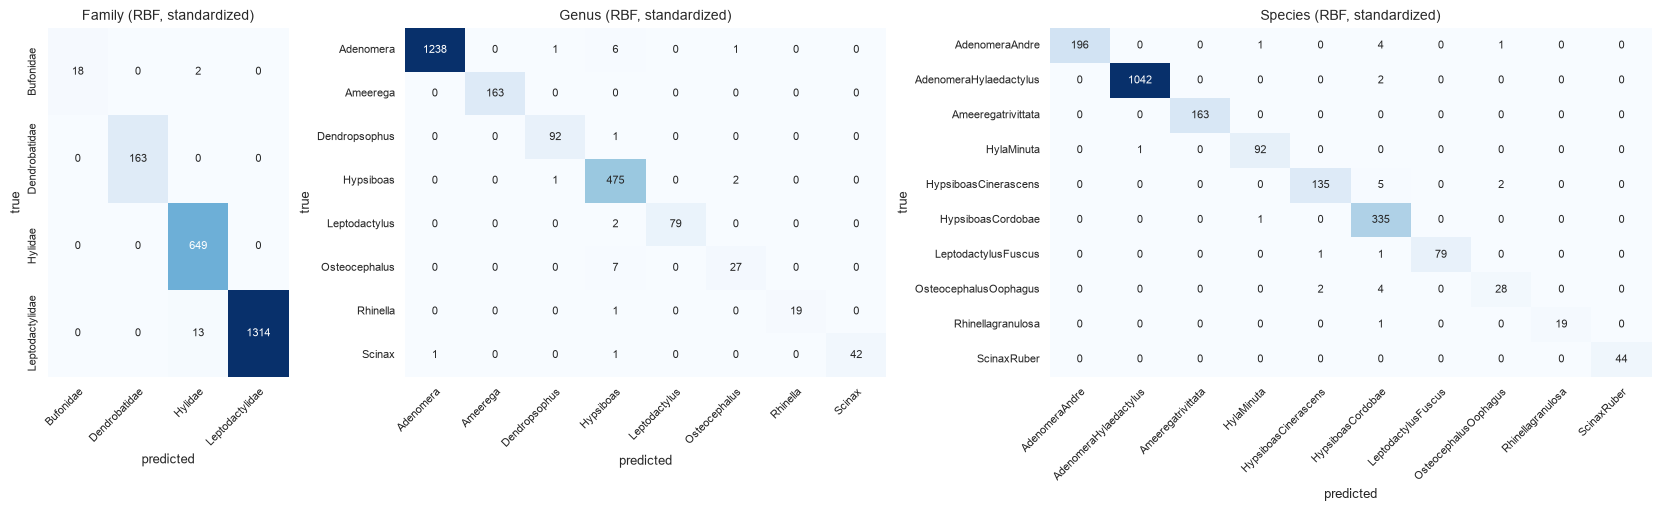

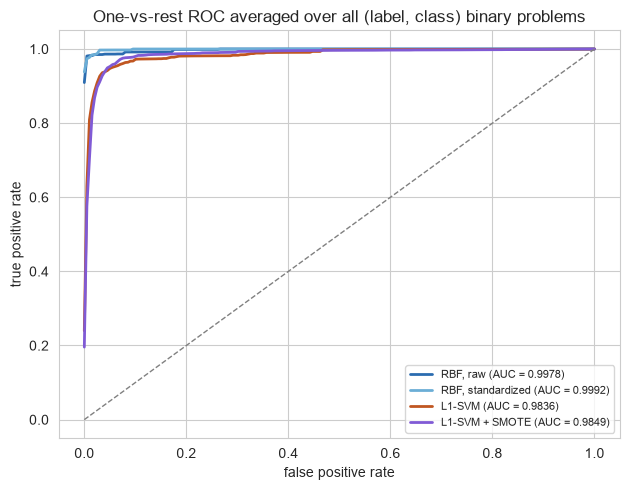

averaged one-vs-rest AUC: {'rbf_raw': 0.9978, 'rbf_std': 0.9992, 'l1': 0.9836, 'smote': 0.9849}


In [10]:
def macro_scores(pred_df, tag):
    rows = []
    for c in label_cols:
        rows.append({
            'label': c,
            'precision': precision_score(Y_te[c], pred_df[c], average='macro', zero_division=0),
            'recall': recall_score(Y_te[c], pred_df[c], average='macro', zero_division=0),
            'f1': f1_score(Y_te[c], pred_df[c], average='macro', zero_division=0),
        })
    t = pd.DataFrame(rows).set_index('label').round(4)
    results[f'{tag}_macro_precision'] = round(float(t['precision'].mean()), 4)
    results[f'{tag}_macro_recall'] = round(float(t['recall'].mean()), 4)
    results[f'{tag}_macro_f1'] = round(float(t['f1'].mean()), 4)
    print(f'--- macro scores: {tag} ---')
    print(t.to_string())
    print()
    return t

_ = macro_scores(pred_rbf_raw, 'rbf_raw')
_ = macro_scores(pred_l1, 'l1')
_ = macro_scores(pred_smote, 'smote')
_ = macro_scores(pred_rbf_std, 'rbf_std')
_ = macro_scores(chain_mode, 'chain')

# multi-label confusion matrices are defined per label: one square matrix each
fig = plt.figure(figsize=(16.5, 5.0), constrained_layout=True)
gs = fig.add_gridspec(1, 3, width_ratios=[4, 8, 10])
for j, c in enumerate(label_cols):
    ax = fig.add_subplot(gs[0, j])
    order = sorted(Y_te[c].unique())
    cm = confusion_matrix(Y_te[c], pred_rbf_std[c], labels=order)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=order, yticklabels=order, annot_kws={'size': 8})
    ax.set_title(f'{c} (RBF, standardized)', fontsize=10)
    ax.set_xlabel('predicted', fontsize=9); ax.set_ylabel('true', fontsize=9)
    ax.tick_params(axis='both', labelsize=8)
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
plt.show()

# one-vs-rest ROC averaged over every (label, class) binary problem. The chain is
# absent here because what I report for it is a majority vote across six runs, and
# a vote carries no score to rank; the four models below all expose per-class scores.
from sklearn.preprocessing import LabelBinarizer

def average_roc(make_clf, Xa, Xb):
    fprs, tprs = [], []
    for c in label_cols:
        lb = LabelBinarizer().fit(Y_tr[c])
        yb = lb.transform(Y_te[c])
        clf = make_clf(c).fit(Xa, Y_tr[c])
        scores = clf.decision_function(Xb)
        for j in range(yb.shape[1]):
            f, t, _ = roc_curve(yb[:, j], scores[:, j])
            fprs.append(f); tprs.append(t)
    grid = np.linspace(0, 1, 200)
    tpr = np.mean([np.interp(grid, f, t) for f, t in zip(fprs, tprs)], axis=0)
    return grid, tpr, float(auc(grid, tpr))

roc_specs = [
    ('RBF, raw', 'rbf_raw',
     lambda c: OneVsRestClassifier(SVC(kernel='rbf', C=best_rbf_raw[c]['estimator__C'],
                                       gamma=best_rbf_raw[c]['estimator__gamma'],
                                       cache_size=600)), X_tr, X_te, '#2b6cb0'),
    ('RBF, standardized', 'rbf_std',
     lambda c: OneVsRestClassifier(SVC(kernel='rbf', C=best_rbf_std[c]['estimator__C'],
                                       gamma=best_rbf_std[c]['estimator__gamma'],
                                       cache_size=600)), X_tr_s, X_te_s, '#6baed6'),
    ('L1-SVM', 'l1',
     lambda c: OneVsRestClassifier(LinearSVC(C=best_l1[c]['estimator__C'], penalty='l1',
                                             dual=False, max_iter=5000, tol=1e-3,
                                             random_state=RNG)), X_tr_s, X_te_s, '#c05621'),
    ('L1-SVM + SMOTE', 'smote',
     lambda c: ImbPipeline([('smote', SMOTE(random_state=RNG, k_neighbors=3)),
                            ('clf', OneVsRestClassifier(
                                LinearSVC(C=best_smote[c]['clf__estimator__C'], penalty='l1',
                                          dual=False, max_iter=5000, tol=1e-3,
                                          random_state=RNG)))]), X_tr_s, X_te_s, '#805ad5'),
]

plt.figure(figsize=(6.4, 5))
for name, tag, make_clf, Xa, Xb, colour in roc_specs:
    g, t, a = average_roc(make_clf, Xa, Xb)
    results[f'{tag}_auc'] = round(a, 4)
    plt.plot(g, t, lw=2, color=colour, label=f'{name} (AUC = {a:.4f})')
plt.plot([0, 1], [0, 1], ls='--', color='grey', lw=1)
plt.xlabel('false positive rate'); plt.ylabel('true positive rate')
plt.title('One-vs-rest ROC averaged over all (label, class) binary problems')
plt.legend(loc='lower right', fontsize=8); plt.tight_layout(); plt.show()

results['micro_auc'] = results['rbf_std_auc']
print('averaged one-vs-rest AUC:', {t: results[f'{t}_auc'] for _, t, *_ in roc_specs})

The macro averages are in the five tables above: the $L_1$ model reaches precision
0.8640 and recall 0.7971, SMOTE moves those to
0.7918 and 0.9246, the standardized RBF model
reaches 0.9852 and 0.9648, and the chain
reaches 0.7611 and 0.7187. The averaged
one-versus-rest AUC runs from 0.9836 ($L_1$) through 0.9849 (SMOTE) and
0.9978 (raw RBF) to 0.9992 (standardized RBF).

Three remarks on reading these numbers.

1. **These metrics do not agree about SMOTE, and the disagreement is the point.**
   Exact match prefers the plain $L_1$ model (0.9176 against 0.8606), but
   macro F1 prefers SMOTE (0.8300 against 0.8202) and so does the
   averaged AUC (0.9849 against 0.9836). The reason is the averaging weight:
   exact match is dominated by the majority classes, which are most of the test
   set, while macro F1 and the averaged AUC give the 68-row classes the same
   weight as the 4,420-row ones. Neither verdict is wrong; they answer different
   questions, and a report that quoted only one of them would be misleading.
2. **Macro recall is the metric that exposes the imbalance.** It averages over
   classes including the 68-row Bufonidae family, so a model that never predicts
   Bufonidae loses recall there no matter how good its overall accuracy looks.
3. **AUC sits above every classification score in the table, and it should.** AUC
   only asks the scores to rank positives above negatives inside each binary
   problem, while exact match demands that the arg-max be right for all three
   labels at once. Ranking is the easier task, which is why the gap exists.

### Model comparison

The table below collects the test-set results of everything trained in 1(b).

In [11]:
rows = []
for name, key in [('SVM RBF, raw', 'rbf_raw'), ('SVM RBF, standardized', 'rbf_std'),
                  ('L1-SVM, standardized', 'l1'), ('L1-SVM + SMOTE', 'smote'),
                  ('Classifier chain (L1)', 'chain')]:
    rows.append({'model': name,
                 'exact match': results[f'{key}_emr'],
                 'hamming distance': results[f'{key}_hd'],
                 'hamming score': results[f'{key}_hs'],
                 'Family acc': results[f'{key}_acc_family'],
                 'Genus acc': results[f'{key}_acc_genus'],
                 'Species acc': results[f'{key}_acc_species']})
comparison = pd.DataFrame(rows).sort_values('exact match', ascending=False).reset_index(drop=True)
display(comparison)
results['best_model'] = comparison.iloc[0]['model']
results['best_emr'] = float(comparison.iloc[0]['exact match'])

,model,exact match,hamming distance,hamming score,Family acc,Genus acc,Species acc
0,"SVM RBF, raw",0.9907,0.0204,0.9932,0.9944,0.9926,0.9926
1,"SVM RBF, standardized",0.9847,0.0301,0.9900,0.9931,0.9889,0.9880
2,Classifier chain (L1),0.9240,0.1927,0.9358,0.9393,0.9347,0.9333
3,"L1-SVM, standardized",0.9176,0.1510,0.9497,0.9398,0.9486,0.9606
4,L1-SVM + SMOTE,0.8606,0.2089,0.9304,0.9152,0.9171,0.9588


# 2. K-Means Clustering: Monte-Carlo Simulation

The second part ignores the labels: k-means is run on the same 22 MFCCs over the
whole data set, and only afterwards do we ask how well the clusters line up with
the true taxonomy. Each of the 50 Monte-Carlo repetitions performs the *entire*
procedure:

1. choose $k \in \{2,\dots,50\}$ automatically (the assignment's range starts at
   1, but both criteria I use are undefined for a single cluster),
2. refit k-means at the chosen $k$ with more restarts,
3. read the majority Family, Genus and Species inside every cluster,
4. predict that majority triplet for every point in the cluster and score it
   against the truth with Hamming distance, Hamming score and Hamming loss.

Repeating the whole procedure — not just the final fit — is the point of the
simulation: it measures how much the answer moves when the initialization and
the $k$ choice move.

**Choosing the criterion matters more than it looks.** I computed the
Calinski-Harabasz index as well, and on this data it has no interior maximum: it
falls from 3,285 at $k=2$ to 726 at $k=50$ and never recovers, with one trivial
bump at $k=15$ (1,399 to 1,419, about 1.4%). Its arg-max is therefore always the
smallest admissible $k$ — technically a valid score, practically useless here.
The silhouette (computed on a 1,500-point sample, because the exact version costs
$O(n^2)$) peaks at $k=4$: 0.3572, against 0.3506 at $k=3$ and 0.3403 at $k=5$.
That peak is narrow — a gap of 0.007 is not a boundary I would defend as sharp —
but it is the value the taxonomy suggests (four families), and it is the value the
50 Monte-Carlo repetitions land on most often, so I select $k$ by silhouette and
keep the Calinski-Harabasz curve in the figure only to document why it is not
used. The narrowness of the peak is one more reason the simulation below reports
the spread of $k$ rather than a single "correct" cluster count.

silhouette picks k=4 (score 0.3572); CH picks k=2 and falls from 3284.6 to 726.0


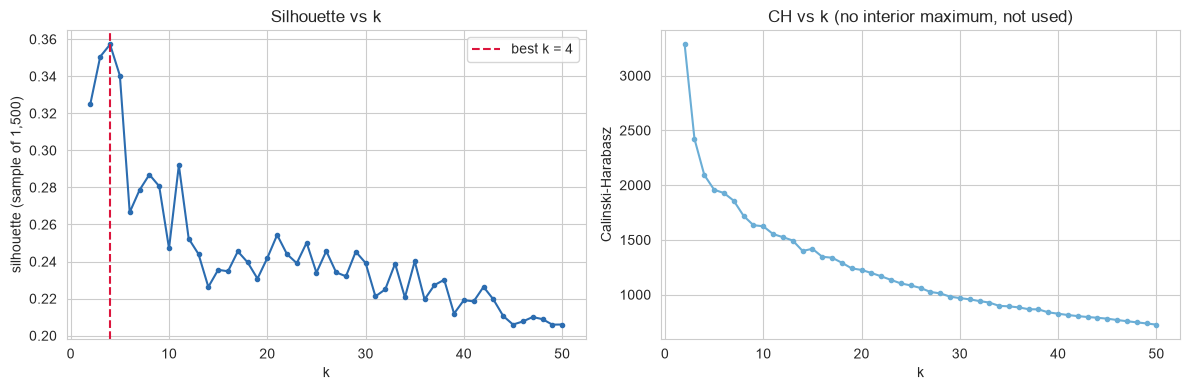

In [12]:
Xk = StandardScaler().fit_transform(X_all)
Yk = Y_all.reset_index(drop=True)
k_range = range(2, 51)

t0 = time.time()
scan = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=3, random_state=0).fit(Xk)
    scan.append({
        'k': k,
        'ch': calinski_harabasz_score(Xk, km.labels_),
        'silhouette': silhouette_score(Xk, km.labels_, sample_size=1500, random_state=0),
    })
scan = pd.DataFrame(scan)
k_sil = int(scan.loc[scan.silhouette.idxmax(), 'k'])
k_ch = int(scan.loc[scan.ch.idxmax(), 'k'])
results['k_sil'] = k_sil
results['k_ch'] = k_ch
results['sil_at_k'] = round(float(scan.silhouette.max()), 4)
results['ch_at_2'] = round(float(scan.loc[scan.k == 2, 'ch'].iloc[0]), 1)
results['ch_at_50'] = round(float(scan.loc[scan.k == 50, 'ch'].iloc[0]), 1)
results['scan_time'] = round(time.time() - t0, 1)
print(f'silhouette picks k={k_sil} (score {results["sil_at_k"]}); '
      f'CH picks k={k_ch} and falls from {results["ch_at_2"]} to {results["ch_at_50"]}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(scan.k, scan.silhouette, marker='o', ms=3, color='#2b6cb0')
axes[0].axvline(k_sil, color='crimson', ls='--', label=f'best k = {k_sil}')
axes[0].set_xlabel('k'); axes[0].set_ylabel('silhouette (sample of 1,500)')
axes[0].set_title('Silhouette vs k'); axes[0].legend()
axes[1].plot(scan.k, scan.ch, marker='o', ms=3, color='#6baed6')
axes[1].set_xlabel('k'); axes[1].set_ylabel('Calinski-Harabasz')
axes[1].set_title('CH vs k (no interior maximum, not used)')
plt.tight_layout(); plt.show()

In [13]:
def kmeans_once(seed):
    best_k, best_sil = None, -np.inf
    for k in k_range:
        km = KMeans(n_clusters=k, n_init=3, random_state=seed).fit(Xk)
        sil = silhouette_score(Xk, km.labels_, sample_size=1500, random_state=seed)
        if sil > best_sil:
            best_sil, best_k = sil, k
    km = KMeans(n_clusters=best_k, n_init=10, random_state=seed).fit(Xk)
    trips = {}
    for c in range(best_k):
        sub = Yk[km.labels_ == c]
        if len(sub) == 0:
            trips[c] = tuple(Yk.iloc[0][label_cols])
        else:
            trips[c] = tuple(sub[col].mode().iloc[0] for col in label_cols)
    pred = pd.DataFrame([trips[l] for l in km.labels_], columns=label_cols)
    hd, hs, hl = hamming_stats(Yk, pred)
    return best_k, best_sil, hd, hs, hl, pred

t0 = time.time()
mc = []
for seed in range(50):
    k, sil, hd, hs, hl, _p = kmeans_once(seed)
    mc.append({'run': seed + 1, 'k': k, 'silhouette': round(sil, 4),
               'hamming_distance': hd, 'hamming_score': hs, 'hamming_loss': hl})
mc_df = pd.DataFrame(mc)
print(f'50 repetitions finished in {time.time()-t0:.0f}s')

results['km_mean_hd'] = round(float(mc_df.hamming_distance.mean()), 4)
results['km_std_hd'] = round(float(mc_df.hamming_distance.std(ddof=1)), 4)
results['km_mean_hs'] = round(float(mc_df.hamming_score.mean()), 4)
results['km_mean_hl'] = round(float(mc_df.hamming_loss.mean()), 4)
results['km_mean_k'] = round(float(mc_df.k.mean()), 1)
results['km_std_k'] = round(float(mc_df.k.std(ddof=1)), 1)
results['km_mode_k'] = int(mc_df.k.mode().iloc[0])
results['km_k_min'] = int(mc_df.k.min())
results['km_k_max'] = int(mc_df.k.max())
results['km_time'] = round(time.time() - t0, 0)

print()
print(f'k chosen: mean {results["km_mean_k"]}, sd {results["km_std_k"]}, '
      f'mode {results["km_mode_k"]}, range [{results["km_k_min"]}, {results["km_k_max"]}]')
print(f'Hamming distance over 50 runs: mean {results["km_mean_hd"]}, sd {results["km_std_hd"]}')
print(f'Hamming score: mean {results["km_mean_hs"]}   Hamming loss: mean {results["km_mean_hl"]}')
print()
print(mc_df.describe().round(4).to_string())

50 repetitions finished in 184s

k chosen: mean 3.9, sd 0.9, mode 4, range [3, 6]
Hamming distance over 50 runs: mean 0.7401, sd 0.1001
Hamming score: mean 0.7533   Hamming loss: mean 0.2467

           run        k  silhouette  hamming_distance  hamming_score  hamming_loss
count  50.0000  50.0000     50.0000           50.0000        50.0000       50.0000
mean   25.5000   3.9400      0.3550            0.7401         0.7533        0.2467
std    14.5774   0.8901      0.0080            0.1001         0.0334        0.0334
min     1.0000   3.0000      0.3306            0.5900         0.7174        0.1967
25%    13.2500   3.0000      0.3509            0.6978         0.7180        0.2326
50%    25.5000   4.0000      0.3564            0.7423         0.7526        0.2474
75%    37.7500   4.0000      0.3610            0.8460         0.7674        0.2820
max    50.0000   6.0000      0.3670            0.8479         0.8033        0.2826


Across the 50 repetitions the chosen $k$ averages 3.9 (sd 0.9, mode
4, range 3-6), and the Hamming distance of the
cluster-majority triplets is **0.7401** with a standard deviation of
**0.1001** over the 50 runs (Hamming score 0.7533, Hamming loss
0.2467). Since each instance carries three labels, a distance of
0.7401 means about 0.74 wrong labels per syllable — three quarters of one
label, on average.

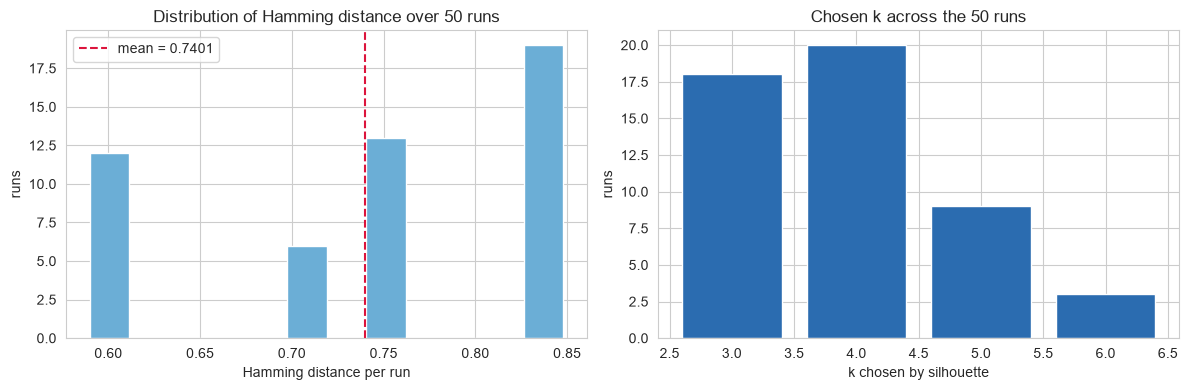

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(mc_df.hamming_distance, bins=12, color='#6baed6', edgecolor='white')
axes[0].axvline(results['km_mean_hd'], color='crimson', ls='--',
                label=f'mean = {results["km_mean_hd"]}')
axes[0].set_xlabel('Hamming distance per run'); axes[0].set_ylabel('runs')
axes[0].set_title('Distribution of Hamming distance over 50 runs')
axes[0].legend()

vc = mc_df.k.value_counts().sort_index()
axes[1].bar(vc.index, vc.values, color='#2b6cb0')
axes[1].set_xlabel('k chosen by silhouette'); axes[1].set_ylabel('runs')
axes[1].set_title('Chosen k across the 50 runs')
plt.tight_layout(); plt.show()

The left histogram is lumpy rather than smooth — the 50 runs produce only a few
distinct Hamming values, so the histogram has four bars rather than a curve — but
its spread is not small: the Hamming distance ranges from 0.59 to 0.85 across runs
while the chosen $k$ stays inside a narrow band (3-6, mode 4). Both the
initialization and the $k$ choice contribute: restarts land in different local
optima, and when the silhouette swings to a neighbouring $k$ the majority triplets
change with it. Reporting the two spreads separately is the useful part of the
simulation — it separates "the number of clusters is unstable" from "the cluster
assignment is unstable at a fixed number of clusters".

In [15]:
# one representative run: cluster sizes and majority triplets
k_best, sil_best, hd_best, hs_best, hl_best, pred_best = kmeans_once(RNG)
km_best = KMeans(n_clusters=k_best, n_init=10, random_state=RNG).fit(Xk)

rows = []
for c in range(k_best):
    mask = km_best.labels_ == c
    sub = Yk[mask]
    rows.append({
        'cluster': c, 'size': int(mask.sum()),
        'family': sub['Family'].mode().iloc[0],
        'genus': sub['Genus'].mode().iloc[0],
        'species': sub['Species'].mode().iloc[0],
        'purity': round(float((sub['Species'] == sub['Species'].mode().iloc[0]).mean()), 3),
    })
cluster_table = pd.DataFrame(rows)
display(cluster_table)
print(f'this run: k={k_best}, Hamming distance={hd_best:.4f}, score={hs_best:.4f}, loss={hl_best:.4f}')
results['km_demo_k'] = int(k_best)
results['km_demo_hd'] = round(hd_best, 4)

,cluster,size,family,genus,species,purity
0,0,3550,Leptodactylidae,Adenomera,AdenomeraHylaedactylus,0.975
1,1,592,Hylidae,Hypsiboas,HypsiboasCinerascens,0.765
2,2,414,Leptodactylidae,Adenomera,AdenomeraAndre,0.884
3,3,643,Leptodactylidae,Adenomera,AdenomeraAndre,0.431
4,4,1996,Hylidae,Hypsiboas,HypsiboasCordobae,0.520


this run: k=5, Hamming distance=0.5903, score=0.8032, loss=0.1968


The representative run picks $k=5$ clusters with Hamming distance
0.5903. The cluster table is the most honest part of this exercise. K-means
reproduces the dominant species almost perfectly — *AdenomeraHylaedactylus* fills
a 3,550-point cluster at 0.975 purity — but it does not so much separate species
as slice them: *HypsiboasCordobae* is the majority of a 1,996-point cluster at
only 0.520 purity, and two different clusters both report *AdenomeraAndre* as
their majority (at 0.884 and 0.431). The rare species never get a cluster of their
own. K-means only sees cepstral geometry, and the taxonomy follows geography and
phylogeny, so the mismatch is expected rather than a bug.

# 3. ISLR 12.6.2 — hierarchical clustering of four observations

The exercise gives four observations and a $4\times4$ dissimilarity matrix, printed
with the diagonal left blank; the diagonal is zero by construction and the matrix
is symmetric, so the twelve printed numbers are only six distinct distances. I
write the matrix out in full before clustering:

| | 1 | 2 | 3 | 4 |
|---|---|---|---|---|
| **1** | 0 | 0.3 | 0.4 | 0.7 |
| **2** | 0.3 | 0 | 0.5 | 0.8 |
| **3** | 0.4 | 0.5 | 0 | 0.45 |
| **4** | 0.7 | 0.8 | 0.45 | 0 |

### (a) Complete linkage

Complete linkage measures the distance between two clusters as the **largest**
dissimilarity between any pair of members.

1. The smallest entry is $d(1,2)=0.3$, so 1 and 2 fuse first at height 0.3.
2. Distances from $\{1,2\}$: to 3 is $\max(d_{13},d_{23})=\max(0.4,0.5)=0.5$;
   to 4 is $\max(0.7,0.8)=0.8$. The smallest remaining distance is 0.45 between
   3 and 4, so $\{3,4\}$ fuses at height 0.45.
3. Finally $\{1,2\}$ and $\{3,4\}$ fuse at
   $\max(0.7,0.8,0.4,0.5)=\mathbf{0.8}$.

### (b) Single linkage

Single linkage uses the **smallest** dissimilarity between clusters.

1. 1 and 2 fuse at 0.3.
2. $\{1,2\}$ to 3 is $\min(0.4,0.5)=0.4$; 3 to 4 is 0.45. So $\{1,2\}$ absorbs 3
   at height 0.4.
3. $\{1,2,3\}$ to 4 is $\min(0.7,0.8,0.45)=\mathbf{0.45}$.

### (c) Two clusters from (a)

The last fusion in (a) joins the two subtrees $\{1,2\}$ and $\{3,4\}$ at height
0.8, so any cut between 0.45 and 0.8 yields two clusters: $\{1,2\}$ and $\{3,4\}$.
This is worth a second look: observation 3 is closer to observation 1 (0.4) than
to observation 4 (0.45), yet complete linkage has already committed to the tight
pair $(3,4)$ at 0.45, so attaching 3 to $\{1,2\}$ is never considered.

### (d) Two clusters from (b)

The single-linkage tree fuses $\{1,2,3\}$ with 4 last, at 0.45, so cutting below
that height again gives $\{1,2,3\}$ and $\{4\}$.

### (e) An equivalent dendrogram with repositioned leaves

At every fusion the two branches may be swapped without changing the clustering:
each internal node is unordered. Swapping the children of the root turns the
complete-linkage tree into one whose leaves read 3, 4, 1, 2 instead of 1, 2, 3, 4,
with identical fusion heights (0.3, 0.45, 0.8). The code below draws both versions
and verifies that the heights are unchanged.

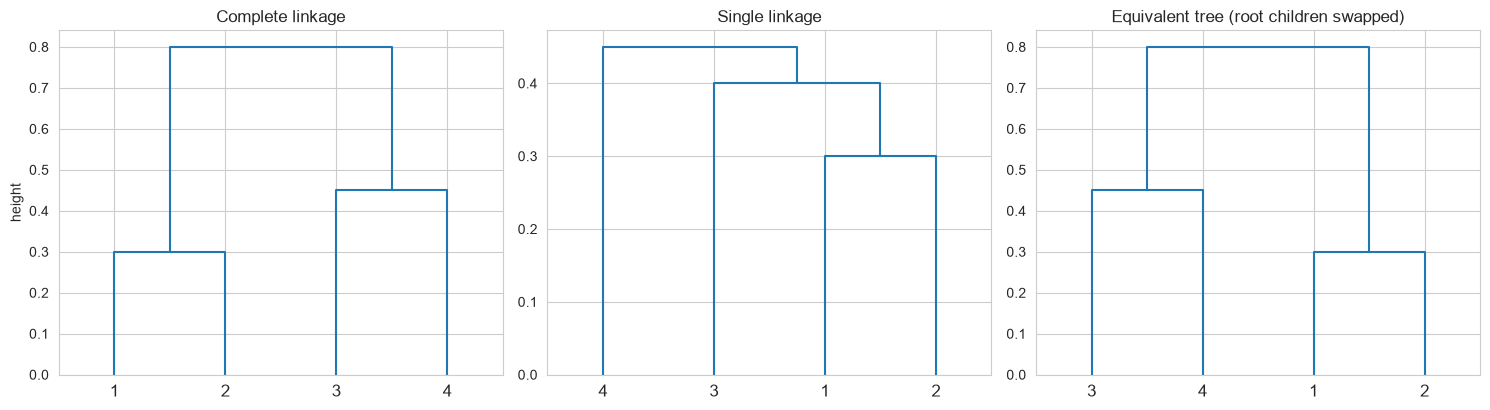

complete-linkage fusion heights : [0.3, 0.45, 0.8]
swapped tree fusion heights     : [0.3, 0.45, 0.8]
single-linkage fusion heights   : [0.3, 0.4, 0.45]
complete, cut at 2 clusters -> [1, 1, 2, 2]
single,   cut at 2 clusters -> [1, 1, 1, 2]


In [16]:
D = np.array([
    [0.00, 0.30, 0.40, 0.70],
    [0.30, 0.00, 0.50, 0.80],
    [0.40, 0.50, 0.00, 0.45],
    [0.70, 0.80, 0.45, 0.00],
])
names = ['1', '2', '3', '4']

Z_complete = linkage(squareform(D), method='complete')
Z_single = linkage(squareform(D), method='single')

# same complete-linkage tree with the root's children swapped: leaves read 3,4,1,2
# rows are kept in non-decreasing height order, so this is a valid linkage matrix
Z_alt = np.array([[0.0, 1.0, 0.30, 2.0],
                  [2.0, 3.0, 0.45, 2.0],
                  [5.0, 4.0, 0.80, 4.0]])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
dendrogram(Z_complete, labels=names, ax=axes[0], color_threshold=0)
axes[0].set_title('Complete linkage'); axes[0].set_ylabel('height')
dendrogram(Z_single, labels=names, ax=axes[1], color_threshold=0)
axes[1].set_title('Single linkage')
dendrogram(Z_alt, labels=names, ax=axes[2], color_threshold=0)
axes[2].set_title('Equivalent tree (root children swapped)')
plt.tight_layout(); plt.show()

print('complete-linkage fusion heights :', np.round(Z_complete[:, 2], 2).tolist())
print('swapped tree fusion heights     :', np.round(Z_alt[:, 2], 2).tolist())
print('single-linkage fusion heights   :', np.round(Z_single[:, 2], 2).tolist())
print('complete, cut at 2 clusters ->', fcluster(Z_complete, 2, criterion='maxclust').tolist())
print('single,   cut at 2 clusters ->', fcluster(Z_single, 2, criterion='maxclust').tolist())

results['islr_complete_heights'] = ', '.join(f'{h:.2f}' for h in Z_complete[:, 2])
results['islr_single_heights'] = ', '.join(f'{h:.2f}' for h in Z_single[:, 2])
results['islr_complete_cut'] = ' / '.join(
    '{' + ','.join(names[i] for i in np.where(fcluster(Z_complete, 2, criterion='maxclust') == c)[0]) + '}'
    for c in (1, 2))
results['islr_single_cut'] = ' / '.join(
    '{' + ','.join(names[i] for i in np.where(fcluster(Z_single, 2, criterion='maxclust') == c)[0]) + '}'
    for c in (1, 2))

The computed fusion heights are **0.30, 0.45, 0.80** for complete linkage
and **0.30, 0.40, 0.45** for single linkage, matching the hand calculation
above. Cutting each tree at two clusters gives {1,2} / {3,4} (complete) and
{1,2,3} / {4} (single) — two *different* partitions of the same four points.

The general lesson, which is the reason the exercise pairs the two methods: single
linkage can "chain" through a sequence of nearby points (observation 3 joins
$\{1,2\}$ at 0.4 because it is only 0.4 from observation 1, even though it is 0.5
from observation 2), producing elongated clusters. Complete linkage insists that
*every* cross-cluster pair be close, so it prefers the compact pair $(3,4)$ at
0.45 and only merges the two groups at 0.8. The two trees therefore differ in
both their second and third fusion heights (0.45/0.8 versus 0.4/0.45), and that
difference is exactly what changes the two-cluster answer.

# Summary

- Binary relevance with an RBF-kernel SVM is the strongest model on this data
  (exact match 0.9907 on raw attributes and 0.9847 after
  standardization, Hamming score 0.9932 and 0.9900); the $L_1$ linear SVM is
  behind (0.9176) but far cheaper and sparse.
- Standardizing barely changes the RBF result once the kernel width is re-tuned —
  the search simply picks a kernel four times as wide ($\sigma = 2$ instead of
  0.5, i.e. $\gamma$ 16 times smaller) — but it is essential for the $L_1$
  penalty, where the scaling decides which coefficients survive.
- SMOTE inside the folds moves the operating point rather than lifting it: macro
  recall rises from 0.7971 to 0.9246 while macro precision
  falls from 0.8640 to 0.7918 and per-label accuracy
  drops slightly (0.9398 to 0.9152 on Family), so exact match
  falls from 0.9176 to 0.8606. Which model counts as better therefore depends
  on the metric: macro F1 and the averaged AUC both prefer the SMOTE model
  (0.8300 against 0.8202, 0.9849 against 0.9836).
- Classifier chains buy consistency rather than accuracy: exact match rises from
  0.9176 to 0.9240 while Species accuracy *falls* from 0.9606 to
  0.9333, because chained triplets are far less often impossible
  (32 of 2,159 against 110).
- Clustering the same features without labels lands at a Hamming distance of
  0.7401 (sd 0.1001) over 50 Monte-Carlo runs: unsupervised structure
  is real but coarser than the taxonomy, which is what one should expect when the
  labels depend on species identity rather than on cepstral geometry alone.
- ISLR 12.6.2: complete linkage fuses at 0.30, 0.45, 0.80, single linkage
  at 0.30, 0.40, 0.45; the two-cluster cuts differ — {1,2} / {3,4} for
  complete linkage against {1,2,3} / {4} for single linkage.